# Import Libraries

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

In [11]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# Exploratory Data Analysis (EDA)

## Dataset Shape

In [12]:
df.shape

(5110, 12)

## Data Types Of Features

In [13]:
df.dtypes

,0
id,int64
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64


## Preview Of Datasets

In [14]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## Statistical Summary Of Datasets

In [15]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


## Target Variable Analysis

### Distribution

In [16]:
df['stroke'].value_counts()

,count
stroke,
0,4861
1,249


<Axes: xlabel='stroke', ylabel='count'>

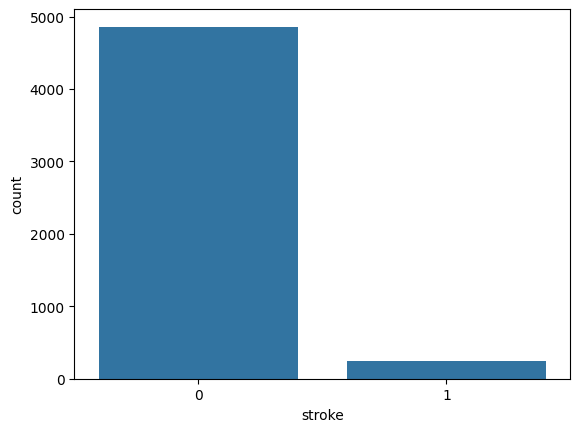

In [17]:
sns.countplot(x = 'stroke', data = df)

In [18]:
stroke_percent = df['stroke'].value_counts(normalize = True) * 100
print(stroke_percent)

stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


#### Conclusion ->
- Have to Handle imbalance

## Numerical Features

### Column -> age

In [19]:
df['age'].describe()

,age
count,5110.000000
mean,43.226614
std,22.612647
min,0.080000
25%,25.000000
50%,45.000000
75%,61.000000
max,82.000000


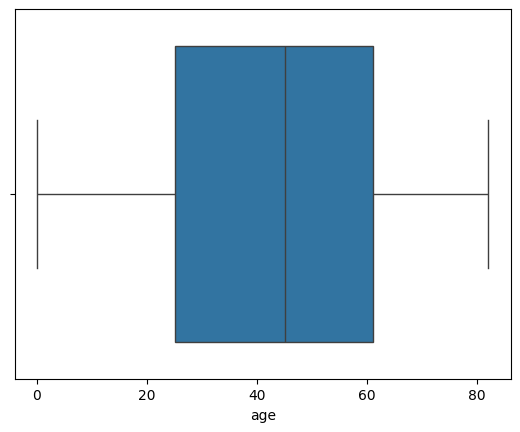

In [20]:
sns.boxplot(x = 'age', data = df)
plt.show()

<Axes: xlabel='age'>

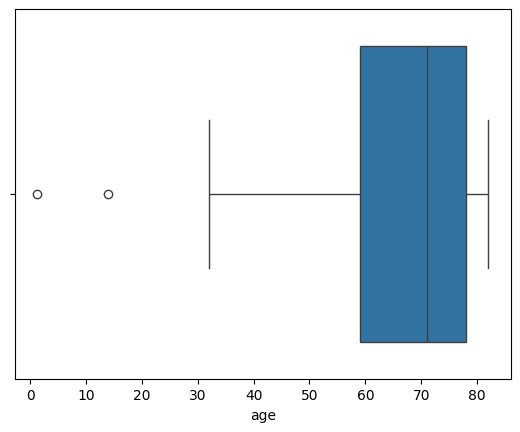

In [21]:
sns.boxplot(x = 'age', data = df[df['stroke'] == 1])

<Axes: xlabel='age'>

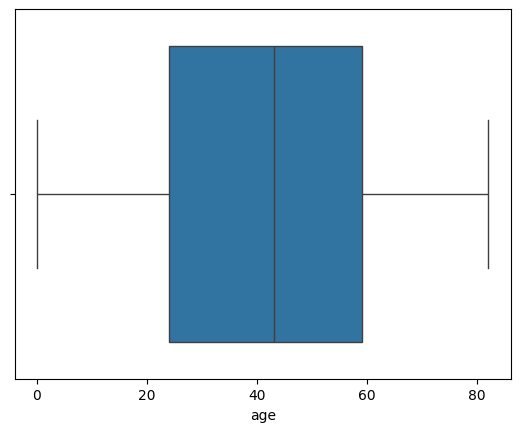

In [22]:
sns.boxplot(x = 'age', data = df[df['stroke'] == 0])

In [23]:
df['age'].skew()

np.float64(-0.1370593225984694)

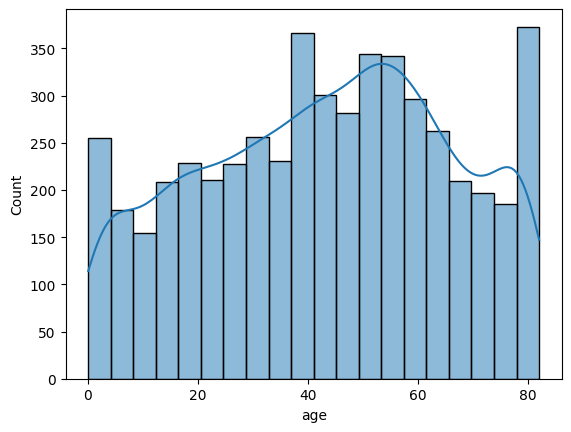

In [24]:
sns.histplot(df['age'], kde = True)
plt.show()

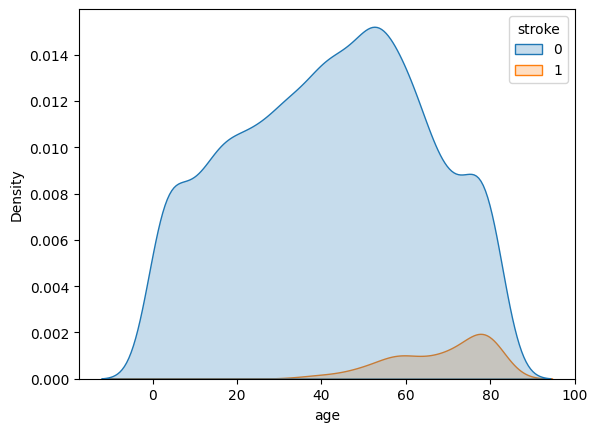

In [25]:
sns.kdeplot(x = 'age', hue = 'stroke', data = df, fill = True)
plt.show()

#### Conclusion ->
- Strong Feature
- Skew is not that high to be handled

### Column -> avg_glucose_level

In [26]:
df['avg_glucose_level'].describe()

,avg_glucose_level
count,5110.000000
mean,106.147677
std,45.283560
min,55.120000
25%,77.245000
50%,91.885000
75%,114.090000
max,271.740000


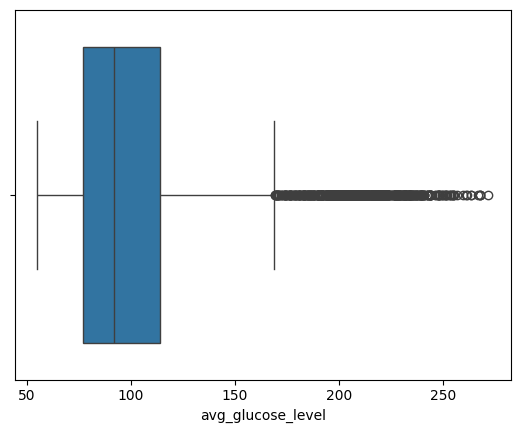

In [27]:
sns.boxplot(x = 'avg_glucose_level', data = df)
plt.show()

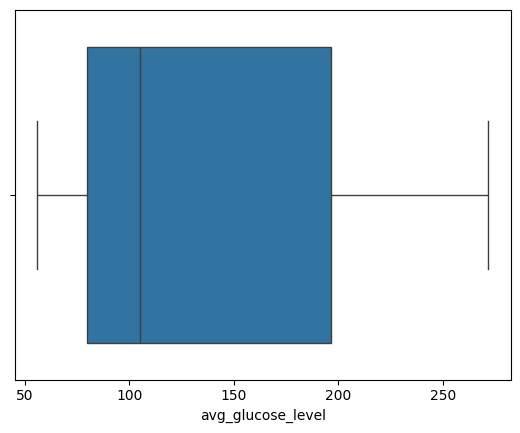

In [28]:
sns.boxplot(x = 'avg_glucose_level', data = df[df['stroke'] == 1])
plt.show()

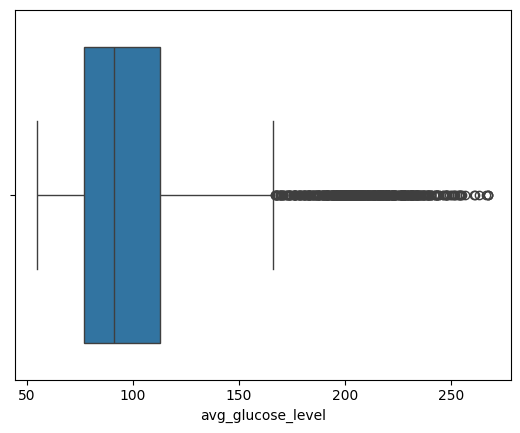

In [29]:
sns.boxplot(x = 'avg_glucose_level', data = df[df['stroke'] == 0])
plt.show()

In [30]:
df['avg_glucose_level'].skew()

np.float64(1.5722838665030459)

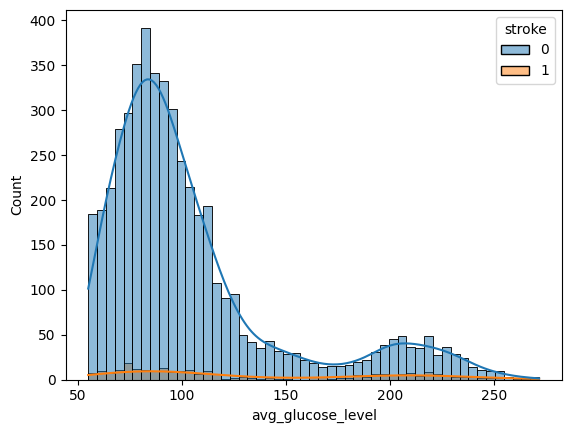

In [31]:
sns.histplot(x = 'avg_glucose_level', hue = 'stroke', data = df, kde = True)
plt.show()

In [32]:
df['avg_glucose_level'].skew()

np.float64(1.5722838665030459)

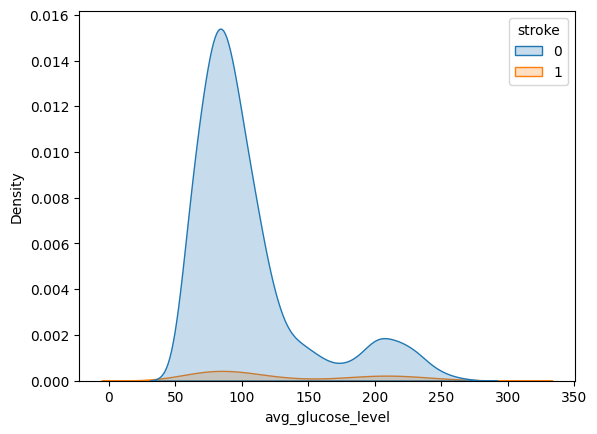

In [33]:
sns.kdeplot(x = 'avg_glucose_level', hue = 'stroke', data = df, fill = True)
plt.show()

#### Conclusion ->
- Have to handle skewness
- Outliers kept -> medically possible

### Column -> bmi

In [34]:
df['bmi'].describe()

,bmi
count,4909.000000
mean,28.893237
std,7.854067
min,10.300000
25%,23.500000
50%,28.100000
75%,33.100000
max,97.600000


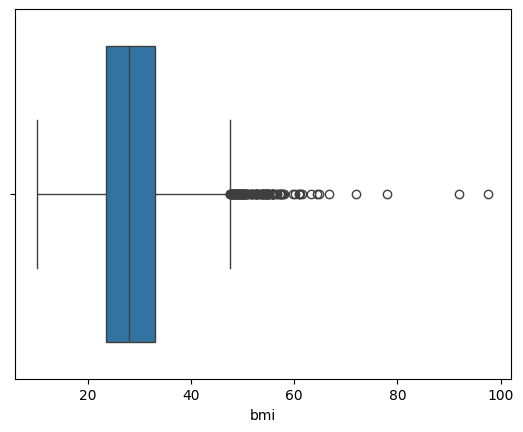

In [35]:
sns.boxplot(x = 'bmi', data = df)
plt.show()

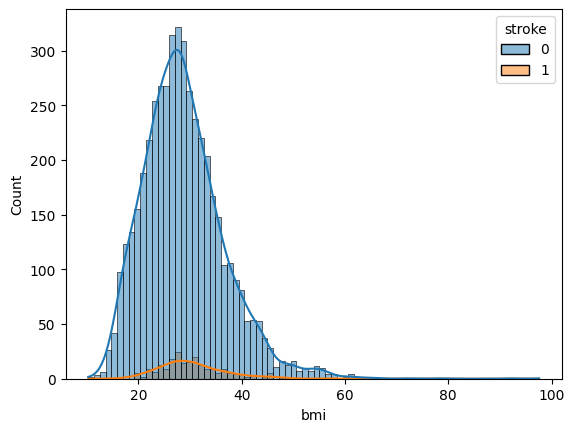

In [36]:
sns.histplot(x = 'bmi', hue = 'stroke', data = df, kde = True)
plt.show()

In [37]:
df['bmi'].skew()

np.float64(1.0553402052962912)

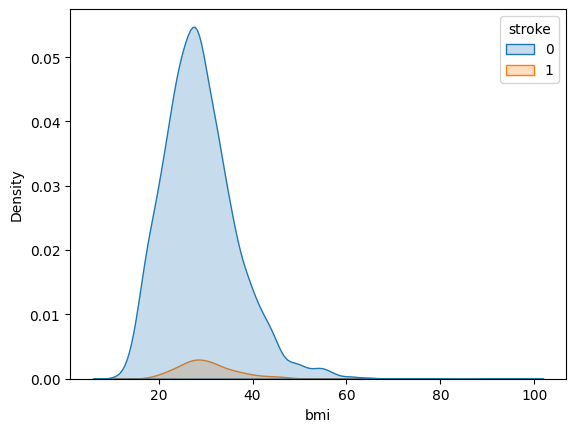

In [38]:
sns.kdeplot(x = 'bmi', hue = 'stroke', data = df, fill = True)
plt.show()

#### Conclusion ->
- Weak predictor than age and glucose
- log transform for Logistic Regression

## Categorical Features

### Column -> gender

In [39]:
df['gender'].describe()

,gender
count,5110
unique,3
top,Female
freq,2994


In [40]:
df['gender'].value_counts()

,count
gender,
Female,2994
Male,2115
Other,1


In [41]:
df['gender'].value_counts(normalize = True) * 100

,proportion
gender,
Female,58.590998
Male,41.389432
Other,0.019569


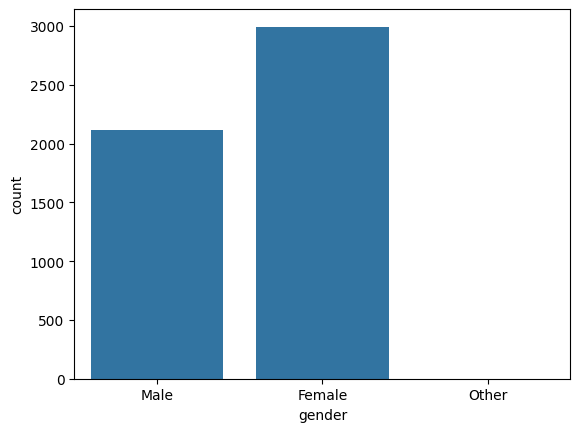

In [42]:
sns.countplot(x = 'gender', data = df)
plt.show()

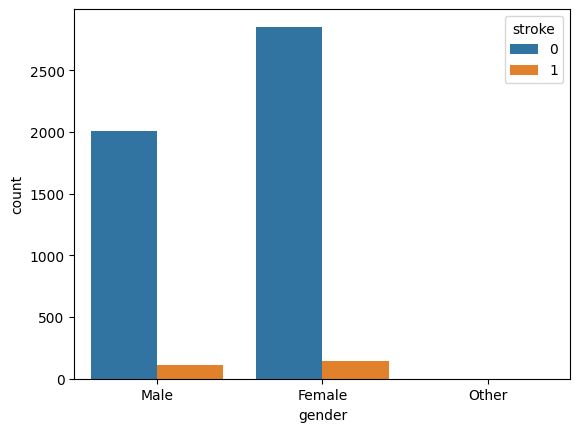

In [43]:
sns.countplot(x = 'gender', hue = 'stroke', data = df)
plt.show()

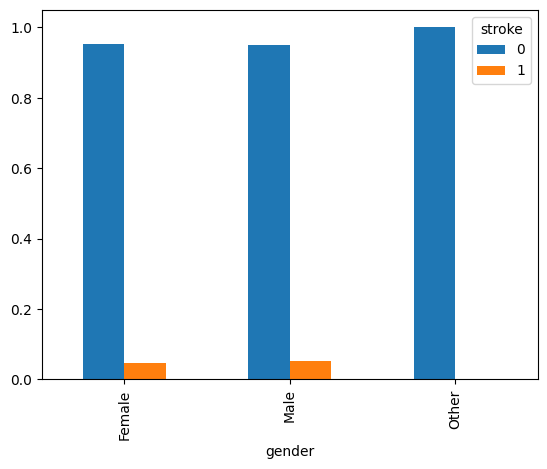

In [44]:
pd.crosstab(df['gender'], df['stroke'], normalize='index').plot(kind='bar')
plt.show()

#### Conclusion ->
- very weak predictor
- Doesn't removing it

### Column -> hypertension

In [45]:
df['hypertension'].value_counts()

,count
hypertension,
0,4612
1,498


In [46]:
df['hypertension'].value_counts(normalize = True) * 100

,proportion
hypertension,
0,90.254403
1,9.745597


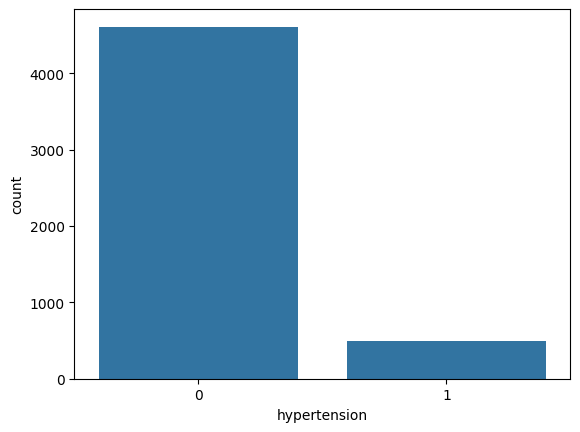

In [47]:
sns.countplot(x = 'hypertension', data = df)
plt.show()

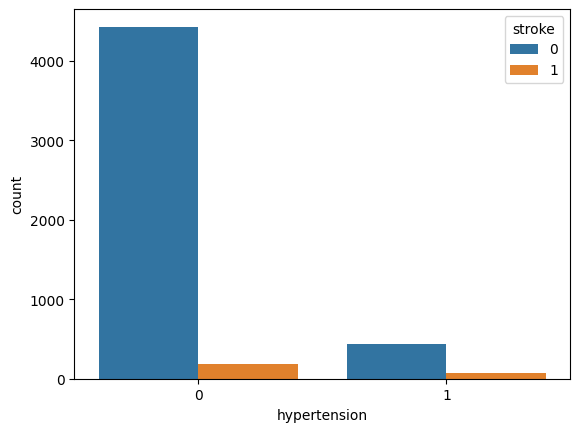

In [48]:
sns.countplot(x = 'hypertension', hue = 'stroke', data = df)
plt.show()

In [49]:
pd.crosstab(df['hypertension'], df['stroke'], normalize = 'index') * 100

stroke,0,1
hypertension,,
0,96.032090,3.967910
1,86.746988,13.253012


#### Conclusion ->
- Importance is High
- Strong Predictor

### Column -> heart_disease

In [50]:
df['heart_disease'].value_counts()

,count
heart_disease,
0,4834
1,276


In [51]:
len(df[(df['heart_disease'] == 1) & (df['stroke'] == 1)])

47

In [52]:
df['heart_disease'].value_counts(normalize = True) * 100

,proportion
heart_disease,
0,94.598826
1,5.401174


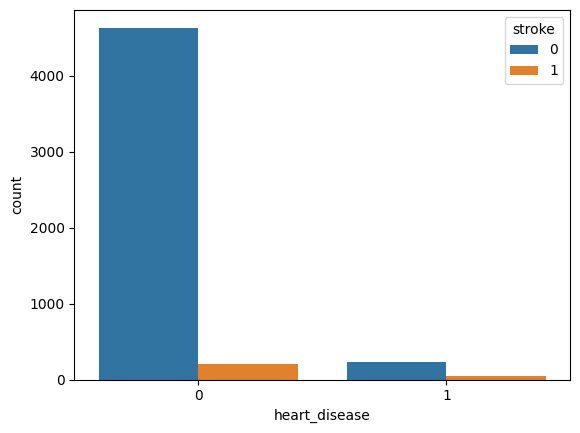

In [53]:
sns.countplot(x = 'heart_disease', hue = 'stroke', data = df)
plt.show()

In [54]:
pd.crosstab(df['heart_disease'], df['stroke'], normalize = 'index') * 100

stroke,0,1
heart_disease,,
0,95.821266,4.178734
1,82.971014,17.028986


#### Conclusion ->
- Strong Predictor

### Column -> ever_married

In [55]:
df['ever_married'].value_counts()

,count
ever_married,
Yes,3353
No,1757


In [56]:
df['ever_married'].value_counts(normalize = True) * 100

,proportion
ever_married,
Yes,65.616438
No,34.383562


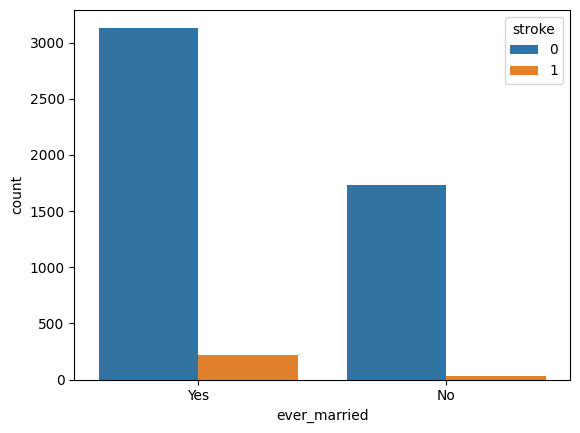

In [57]:
sns.countplot(x = 'ever_married', hue = 'stroke', data = df)
plt.show()

In [58]:
pd.crosstab(df['ever_married'], df['stroke'], normalize = 'index') * 100

stroke,0,1
ever_married,,
No,98.349459,1.650541
Yes,93.438712,6.561288


#### Conclusion ->
- Mid-High Importance
- Influenced By Age

### Column -> work_type

In [59]:
df['work_type'].describe()

,work_type
count,5110
unique,5
top,Private
freq,2925


In [60]:
df['work_type'].value_counts()

,count
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22


In [61]:
df['work_type'].value_counts(normalize = True) * 100

,proportion
work_type,
Private,57.240705
Self-employed,16.027397
children,13.444227
Govt_job,12.857143
Never_worked,0.430528


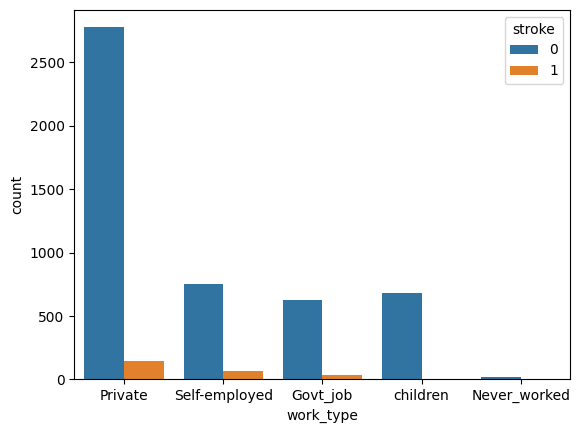

In [62]:
sns.countplot(x = 'work_type', hue = 'stroke', data = df)
plt.show()

In [63]:
pd.crosstab(df['work_type'], df['stroke'], normalize = 'index') * 100

stroke,0,1
work_type,,
Govt_job,94.977169,5.022831
Never_worked,100.000000,0.000000
Private,94.905983,5.094017
Self-employed,92.063492,7.936508
children,99.708879,0.291121


#### Conclusion ->
- Medium
- Remove Never_worked or replace it with children

### Column -> Residence_type

In [64]:
df['Residence_type'].value_counts()

,count
Residence_type,
Urban,2596
Rural,2514


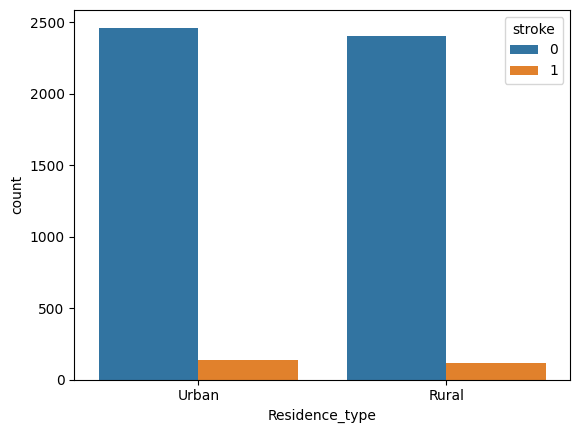

In [65]:
sns.countplot(x = 'Residence_type', hue = 'stroke', data = df)
plt.show()

In [66]:
pd.crosstab(df['Residence_type'], df['stroke'], normalize = 'index') * 100

stroke,0,1
Residence_type,,
Rural,95.465394,4.534606
Urban,94.799692,5.200308


#### Conclusion ->
- Very Low Predictive
- Will increase model complexity unnecessarily
- Drop It

### Column ->

In [67]:
df['smoking_status'].value_counts()

,count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789


In [68]:
df['smoking_status'].value_counts(normalize = True) * 100

,proportion
smoking_status,
never smoked,37.025440
Unknown,30.215264
formerly smoked,17.318982
smokes,15.440313


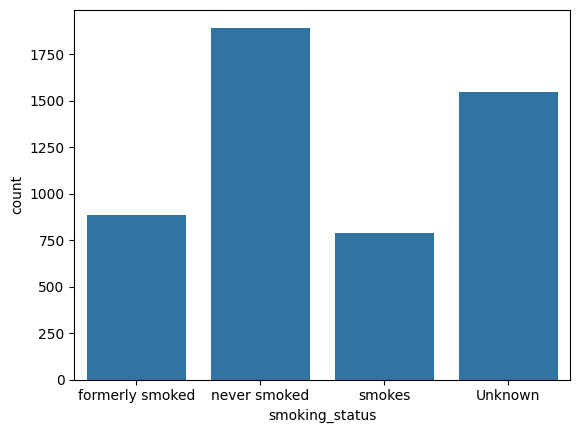

In [69]:
sns.countplot(x = 'smoking_status', data = df)
plt.show()

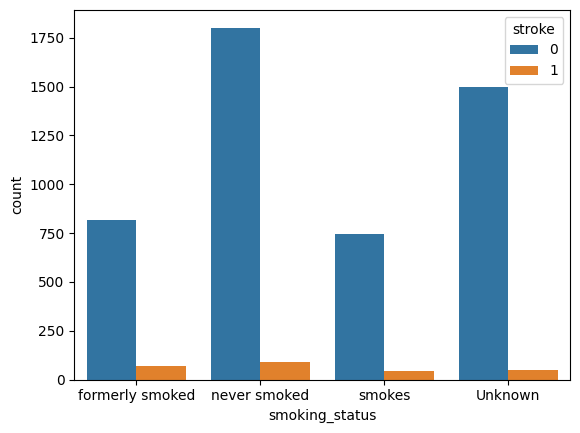

In [70]:
sns.countplot(x = 'smoking_status', hue = 'stroke', data = df)
plt.show()

In [71]:
pd.crosstab(df['smoking_status'], df['stroke'], normalize = 'index') * 100

stroke,0,1
smoking_status,,
Unknown,96.955959,3.044041
formerly smoked,92.090395,7.909605
never smoked,95.243129,4.756871
smokes,94.676806,5.323194


#### Conclusion ->
- Highly Predictive
- Can create a new Column is_Smoking_Unknown